In [31]:
import re
import requests
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import saka

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, classification_report,ConfusionMatrixDisplay)

In [2]:
df = pd.read_csv(r"Downloads/ulasan_ig_playstore_2bulan_id.csv")

In [3]:
df.head()

,review_id,user_name,rating,comment,likes,app_version,date
0,23ccef25-aa62-4cb1-8027-9de283f23df8,Alfian Bone,4,jaringan ngeleg sekali,5,451.0.0.53.80,2026-10-14 08:12:51 UTC
1,c0b7128a-97ec-4994-acbb-f14da199b78e,Love,5,"Teruntuk Instagram, mohon kembalikan feed yang...",3,449.0.0.52.84,2026-10-14 08:12:14 UTC
2,91f91be8-5805-49db-9aff-4da45536d4b3,Putri Astuti,1,"tiap scroll reels banyak iklan, terus langsung...",11,450.0.0.50.77,2026-10-14 08:10:41 UTC
3,b766aa97-c4c4-49ea-9d77-e93a80808bf6,Gembul Gemoy,1,"ga bisa nonton bokep,kata temen aku bisa,pas a...",4,NaN,2026-10-14 08:10:28 UTC
4,9b2a4d4d-bc33-4147-bdd2-038548cae682,Boy Ike,5,sangat puas,1,451.0.0.53.80,2026-10-14 08:04:46 UTC


# Data Understanding

In [4]:
jumlah_baris = len(df)
print(f"   Total baris data: {jumlah_baris}")

   Total baris data: 29257


In [5]:
jumlah_duplikasi = df.duplicated().sum()
print(f"   Jumlah baris duplikat: {jumlah_duplikasi}")

   Jumlah baris duplikat: 0


In [6]:
data_kosong = df.isnull().sum()
print(data_kosong)

review_id          0
user_name          0
rating             0
comment            0
likes              0
app_version    11299
date               0
dtype: int64


   A. Distribusi Skor/Rating:


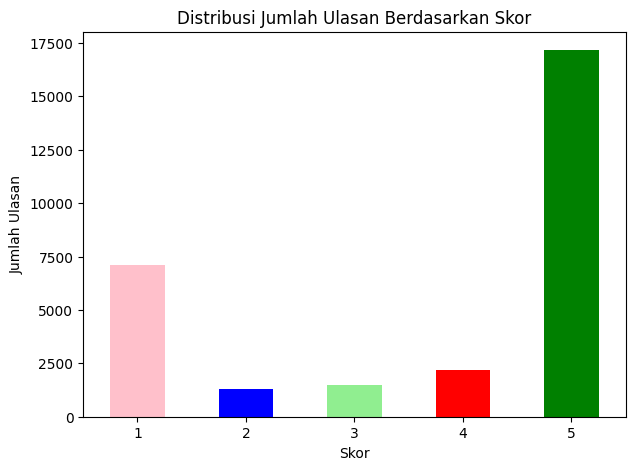

In [7]:
print("   A. Distribusi Skor/Rating:")
plt.figure(figsize=(7, 5))
df['rating'].value_counts().sort_index().plot(kind='bar', color=['pink', 'blue', 'lightgreen', 'red', 'green'])
plt.title('Distribusi Jumlah Ulasan Berdasarkan Skor')
plt.xlabel('Skor')
plt.ylabel('Jumlah Ulasan')
plt.xticks(rotation=0)
plt.show()

# Data Preprocessing

In [11]:
def cleaning(text):
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#\w+", " ", text)
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"(.)\1{2,}", r"\1", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def casefolding(text):
    return text.lower()

def normalisasi(text):
    return saka.normalize(text)

def tokenisasi(text):
    return saka.tokenize(text)

PENGECUALIAN = {"tidak", "bukan", "belum", "tak", "kurang", "nggak", "gak", "jangan"}
STOPWORDS = set(saka.get_stopwords("id")) - PENGECUALIAN

def hapus_stopwords(tokens):
    return [t for t in tokens if t not in STOPWORDS]

df["cleaning"]    = df["comment"].progress_apply(cleaning)
df["casefolding"] = df["cleaning"].progress_apply(casefolding)
df["normalisasi"] = df["casefolding"].progress_apply(normalisasi)
df["tokenisasi"]  = df["normalisasi"].progress_apply(tokenisasi)
df["stopwords"]   = df["tokenisasi"].progress_apply(hapus_stopwords)
df["text_clean"]  = df["stopwords"].apply(lambda t: " ".join(t))

df = df[df["text_clean"].str.strip() != ""].reset_index(drop=True)

100%|██████████| 28412/28412 [00:00<00:00, 356554.05it/s]


In [12]:
df.head()

,review_id,user_name,rating,comment,likes,app_version,date,cleaning,casefolding,normalisasi,tokenisasi,stopwords,text_clean
0,23ccef25-aa62-4cb1-8027-9de283f23df8,Alfian Bone,4,jaringan ngeleg sekali,5,451.0.0.53.80,2026-10-14 08:12:51 UTC,jaringan ngeleg sekali,jaringan ngeleg sekali,jaringan ngeleg sekali,"[jaringan, ngeleg, sekali]","[jaringan, ngeleg]",jaringan ngeleg
1,c0b7128a-97ec-4994-acbb-f14da199b78e,Love,5,"Teruntuk Instagram, mohon kembalikan feed yang...",3,449.0.0.52.84,2026-10-14 08:12:14 UTC,Teruntuk Instagram mohon kembalikan feed yang ...,teruntuk instagram mohon kembalikan feed yang ...,teruntuk instagram mohon kembalikan feed yang ...,"[teruntuk, instagram, mohon, kembalikan, feed,...","[teruntuk, instagram, mohon, kembalikan, feed,...",teruntuk instagram mohon kembalikan feed rasio...
2,91f91be8-5805-49db-9aff-4da45536d4b3,Putri Astuti,1,"tiap scroll reels banyak iklan, terus langsung...",11,450.0.0.50.77,2026-10-14 08:10:41 UTC,tiap scroll reels banyak iklan terus langsung ...,tiap scroll reels banyak iklan terus langsung ...,tiap scroll reels banyak iklan terus langsung ...,"[tiap, scroll, reels, banyak, iklan, terus, la...","[scroll, reels, iklan, langsung, masuk, profil...",scroll reels iklan langsung masuk profil whats...
3,b766aa97-c4c4-49ea-9d77-e93a80808bf6,Gembul Gemoy,1,"ga bisa nonton bokep,kata temen aku bisa,pas a...",4,NaN,2026-10-14 08:10:28 UTC,ga bisa nonton bokep kata temen aku bisa pas a...,ga bisa nonton bokep kata temen aku bisa pas a...,ga bisa nonton porno kata teman aku bisa pas a...,"[ga, bisa, nonton, porno, kata, teman, aku, bi...","[ga, nonton, porno, teman, pas, download, eh, ...",ga nonton porno teman pas download eh tidak no...
4,9b2a4d4d-bc33-4147-bdd2-038548cae682,Boy Ike,5,sangat puas,1,451.0.0.53.80,2026-10-14 08:04:46 UTC,sangat puas,sangat puas,sangat puas,"[sangat, puas]",[puas],puas


# Labeling

In [17]:
tqdm.pandas()

BASE = "https://raw.githubusercontent.com/masdevid/ID-OpinionWords/master/"

def load_words(nama_file):
    teks = requests.get(BASE + nama_file, timeout=30).text
    return {w.strip().lower() for w in teks.splitlines()
            if w.strip() and not w.startswith(";")}

POSITIF = load_words("positive.txt")
NEGATIF = load_words("negative.txt")
print(len(POSITIF), len(NEGATIF))   # cek jumlahnya masuk akal

NEGASI = {"tidak", "bukan", "belum", "tak", "kurang", "nggak", "gak", "jangan"}

def skor_sentimen(teks):
    tokens = teks.split()
    skor = 0
    for i, t in enumerate(tokens):
        nilai = 1 if t in POSITIF else -1 if t in NEGATIF else 0
        if nilai and i > 0 and tokens[i - 1] in NEGASI:   
            nilai = -nilai
        skor += nilai
    return skor

def label_sentimen(skor):
    return "positif" if skor > 0 else "negatif" if skor < 0 else "netral"

df["skor"]  = df["text_clean"].progress_apply(skor_sentimen)
df["label"] = df["skor"].apply(label_sentimen)

print(df["label"].value_counts())

1178 2389


100%|██████████| 28412/28412 [00:00<00:00, 230044.93it/s]

label
netral     13261
positif    10025
negatif     5126
Name: count, dtype: int64


# Persiapan ML

In [18]:
X = df["text_clean"]
y = df["label"]

print(y.value_counts(normalize=True))   # cek sebaran kelas

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y         )
print(f"Train: {len(X_train)} | Test: {len(X_test)}")

label
netral     0.466739
positif    0.352844
negatif    0.180417
Name: proportion, dtype: float64
Train: 22729 | Test: 5683


In [21]:
tfidf = TfidfVectorizer(
    max_features=5000,      
    ngram_range=(1, 3),     
    min_df=2,               
    max_df=0.95             
)

X_train_tfidf = tfidf.fit_transform(X_train)  
X_test_tfidf  = tfidf.transform(X_test)

# ML

In [27]:
svm = LinearSVC(class_weight="balanced", random_state=42)
svm.fit(X_train_tfidf, y_train)

y_pred = svm.predict(X_test_tfidf)

In [28]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9122
              precision    recall  f1-score   support

     negatif       0.83      0.88      0.86      1025
      netral       0.92      0.91      0.91      2653
     positif       0.95      0.93      0.94      2005

    accuracy                           0.91      5683
   macro avg       0.90      0.91      0.90      5683
weighted avg       0.91      0.91      0.91      5683



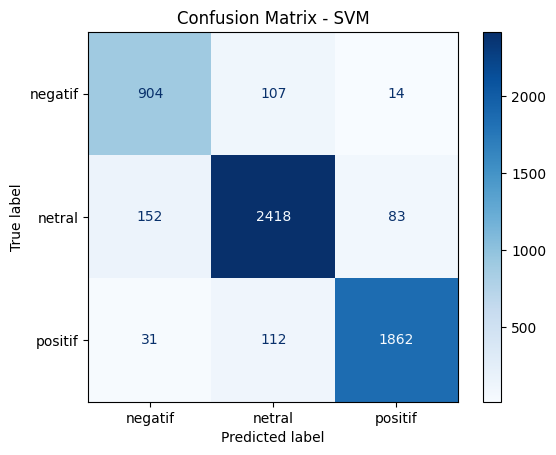

In [29]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Confusion Matrix - SVM")
plt.show()

# Download

In [30]:
joblib.dump(svm, "svm_model.pkl")
joblib.dump(tfidf, "tfidf.pkl")

['tfidf.pkl']